In [16]:
import os
os.environ["GCSFS_EXPERIMENTAL_ZB_HNS_SUPPORT"] = "false"

In [17]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [18]:
plt.rcParams['figure.figsize'] = 12, 6

In [19]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


## Year × Latitude heatmap of the warming gap

**How it works.** The map from Project 3 shows *where* the gap is for one moment. This chart squeezes the whole 2020–2100 story into a single picture:

- **x-axis:** year (2020 → 2100), one column per year
- **y-axis:** latitude (South Pole at the bottom, North Pole at the top), one row per 2° model band
- **color:** the warming gap, SSP5-8.5 minus SSP1-2.6 in °C, using the same red–blue diverging scale as the map (white = no difference)

To get one number per (year, latitude) cell we:

1. **Average around the globe at each latitude** (over all longitudes). This is called the *zonal mean*. We lose east–west detail (that is the map's job) but gain the full time axis.
2. **Average the 12 months of each year** so the seasons don't add noise.
3. **Subtract** SSP1-2.6 from SSP5-8.5.
4. **Smooth with a 10-year rolling mean** so the long-term signal isn't hidden by year-to-year weather noise. Each year is averaged with the 5 years before it and the 4 after it (2050 = mean of 2045–2054). We include 2015–2019 in this step so 2020 also gets a full window, then show only 2020 onward. At the other end the data stops in 2100, so the last few years use a shorter window (2100 = mean of 2095–2100).

Reading it: a **vertical slice** is the latitude profile for one year; a **horizontal slice** is how the gap grows over time at one latitude.

### Load the three scenarios

We use the `r1i1p3f1` run, which is the same run as Project 3's `prepare_data.py`. Note that the first row the catalog returns for GISS-E2-1-G is a run that only covers 2020–2024, so we pick the run explicitly.

In [20]:
SCENARIOS = ['ssp126', 'ssp245', 'ssp585']
MEMBER = 'r1i1p3f1'

runs = df.query(
    "source_id == 'GISS-E2-1-G' & table_id == 'Amon' & variable_id == 'tas'"
    " & member_id == @MEMBER & experiment_id in @SCENARIOS"
).set_index('experiment_id')

gcs = gcsfs.GCSFileSystem(token='anon')
datasets = {
    s: xr.open_zarr(gcs.get_mapper(runs.loc[s, 'zstore']), consolidated=True)
    for s in SCENARIOS
}
datasets['ssp585'].tas

<xarray.DataArray 'tas' (time: 1032, lat: 90, lon: 144)> Size: 53MB
[13374720 values with dtype=float32]
Coordinates:
  * time     (time) object 8kB 2015-01-16 12:00:00 ... 2100-12-16 12:00:00
  * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    height   float64 8B ...
Attributes:
    cell_measures:  area: areacella
    cell_methods:   area: time: mean
    comment:        near-surface (usually, 2 meter) air temperature
    history:        2020-01-30T05:40:36Z altered by CMOR: Treated scalar dime...
    long_name:      Near-Surface Air Temperature
    standard_name:  air_temperature
    units:          K

### Collapse to one value per year and latitude

This downloads the full monthly grids (about a minute), then reduces each scenario from `(time, lat, lon)` to `(year, lat)`.

We load from **2015** (the first year of the model run) even though the chart starts in **2020**. The extra years let the 10-year smoothing for 2020–2024 use a full window: for example, 2020 averages 2015–2024 instead of only 2020–2024. After smoothing, everything before 2020 is dropped.

In [21]:
def year_by_latitude(ds):
    # Start in 2015 (where the model run begins) so the early years get a full
    # 10-year smoothing window. We trim back to 2020 after smoothing.
    tas_c = ds.tas.sel(time=slice('2015', '2100')) - 273.15     # Kelvin -> °C
    zonal = tas_c.mean('lon')                                   # 1. average around each latitude circle
    return zonal.groupby('time.year').mean().load()             # 2. average the 12 months of each year

zonal = xr.Dataset({s: year_by_latitude(ds) for s, ds in datasets.items()})
zonal

<xarray.Dataset> Size: 94kB
Dimensions:  (lat: 90, year: 86)
Coordinates:
  * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
  * year     (year) int64 688B 2015 2016 2017 2018 2019 ... 2097 2098 2099 2100
    height   float64 8B 2.0
Data variables:
    ssp126   (year, lat) float32 31kB -49.04 -44.56 -38.52 ... -14.89 -15.07
    ssp245   (year, lat) float32 31kB -46.37 -42.84 -37.48 ... -14.02 -14.22
    ssp585   (year, lat) float32 31kB -46.87 -42.42 -36.94 ... -8.22 -8.527

In [22]:
SHOW = slice(2020, 2100)                                                    # years shown on the chart

gap_all = zonal['ssp585'] - zonal['ssp126']                                 # 3. the warming gap (2015–2100)
gap_10yr = (gap_all
            .rolling(year=10, center=True, min_periods=5).mean()            # 4. 10-year smoothing, using 2015–2019 too
            .sel(year=SHOW))                                                #    then keep only 2020 onward
gap = gap_all.sel(year=SHOW)                                                # raw annual gap, 2020 onward

print('shape (years, latitudes):', gap.shape)
for year in [2030, 2050, 2070, 2090]:
    g = gap_10yr.sel(year=year)
    print(f"{year}: largest gap {float(g.max()):4.1f}°C at {float(g.idxmax('lat')):+5.0f}°, "
          f"smallest {float(g.min()):4.1f}°C at {float(g.idxmin('lat')):+5.0f}°")

shape (years, latitudes): (81, 90)
2030: largest gap  0.2°C at    -1°, smallest -0.4°C at   -81°
2050: largest gap  1.7°C at   -89°, smallest  0.0°C at   +43°
2070: largest gap  3.0°C at   -89°, smallest  0.6°C at   +51°
2090: largest gap  4.7°C at   -89°, smallest  1.5°C at   +51°


### The heatmap

Contour lines mark where the gap first reaches 1, 2, 3 … °C, so you can read off *when* each latitude crosses a threshold.

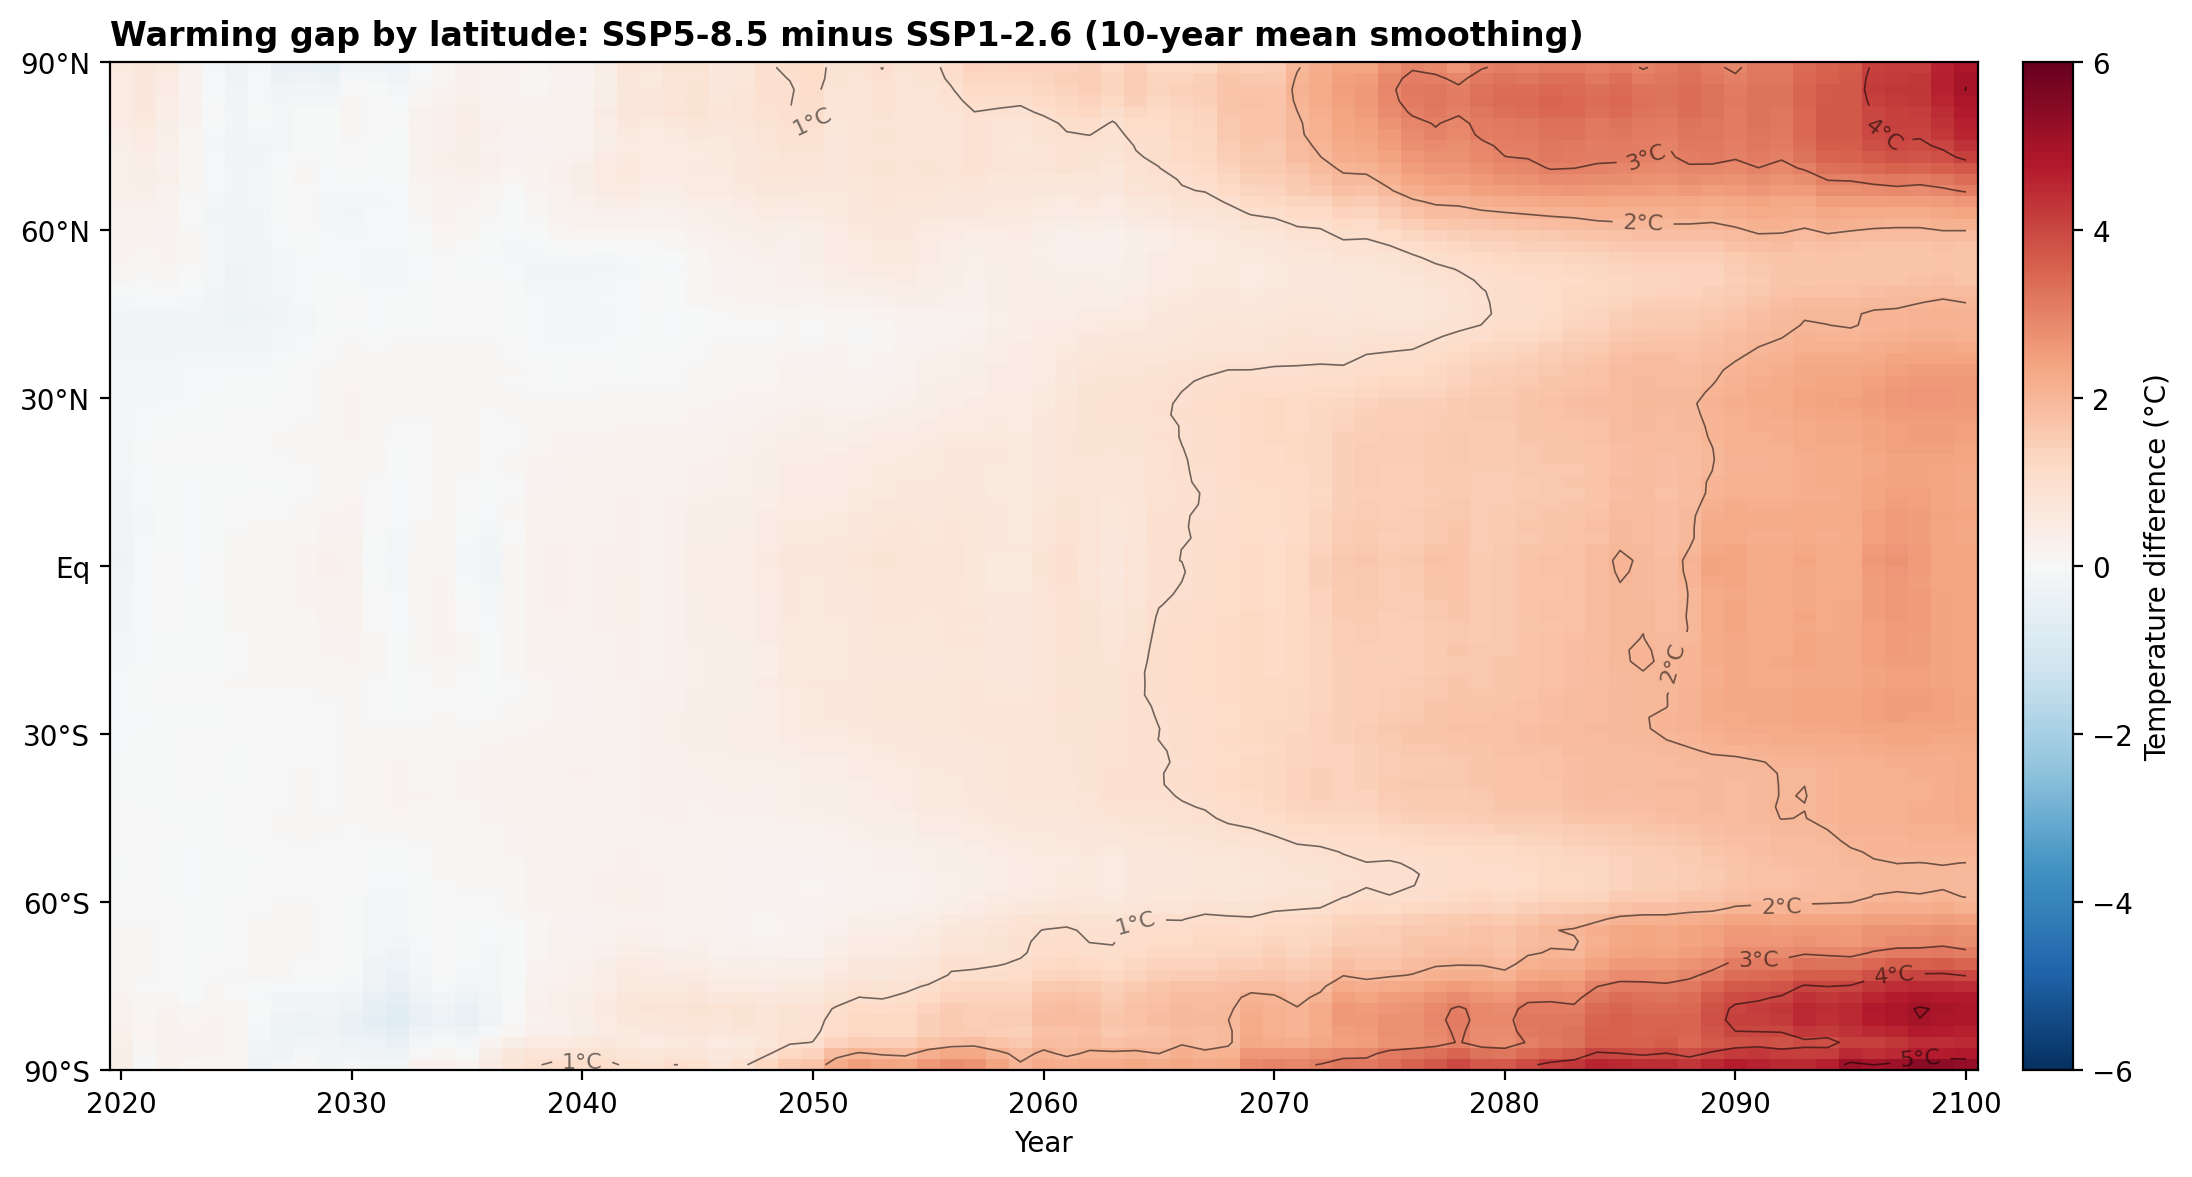

In [27]:
LIMIT = float(np.ceil(abs(gap_10yr).max()))     # symmetric color limits so 0 stays white
LAT_TICKS = [-90, -60, -30, 0, 30, 60, 90]
LAT_LABELS = ['90°S', '60°S', '30°S', 'Eq', '30°N', '60°N', '90°N']

fig, ax = plt.subplots(figsize=(12, 6))
mesh = ax.pcolormesh(gap_10yr.year, gap_10yr.lat, gap_10yr.T,
                     cmap='RdBu_r', vmin=-LIMIT, vmax=LIMIT, shading='nearest')
contours = ax.contour(gap_10yr.year, gap_10yr.lat, gap_10yr.T,
                      levels=np.arange(1, LIMIT), colors='k', linewidths=0.6, alpha=0.55)
ax.clabel(contours, fmt='%d°C', fontsize=8)

ax.set_yticks(LAT_TICKS, LAT_LABELS)
ax.set_xlabel('Year')
ax.set_title('Warming gap by latitude: SSP5-8.5 minus SSP1-2.6 (10-year mean smoothing)', loc='left', fontweight='bold')
fig.colorbar(mesh, ax=ax, label='Temperature difference (°C)', pad=0.02)
fig.tight_layout()
plt.show()

### What the heatmap shows

- **The futures start together.** Until about 2040 the gap is within a few tenths of a degree at every latitude, so the map's early years are mostly noise.
- **The gap opens almost everywhere after about 2050** and passes 2°C across most of the tropics and mid-latitudes between about 2070 and 2085.
- **The poles pull away fastest.** The largest gap is over Antarctica (about 4.7°C near 89°S by the 2090s), followed by the Arctic (about 3°C around 75–80°N).
- **Two latitude bands lag behind:** around 50°N (only about 1.5°C by the 2090s, the smallest gap at any latitude) and around 55°S. These line up with the North Atlantic and Southern Ocean, where deep ocean mixing slows surface warming. That explanation is our hypothesis; check it against the map.
- **Caveat for the design:** the y-axis is evenly spaced in latitude, which makes the poles look bigger than their share of the Earth's surface (latitudes beyond 60° cover only about 13% of the planet). The D3 version could space rows by `sin(latitude)` to give each band its true area weight.

### Why smooth? Raw annual values vs. 10-year mean

On the left, every year is its own column, so random weather variability shows up as speckle (especially at the poles). The 10-year mean on the right keeps the trend and removes most of the noise. In the D3 version this could be a toggle.

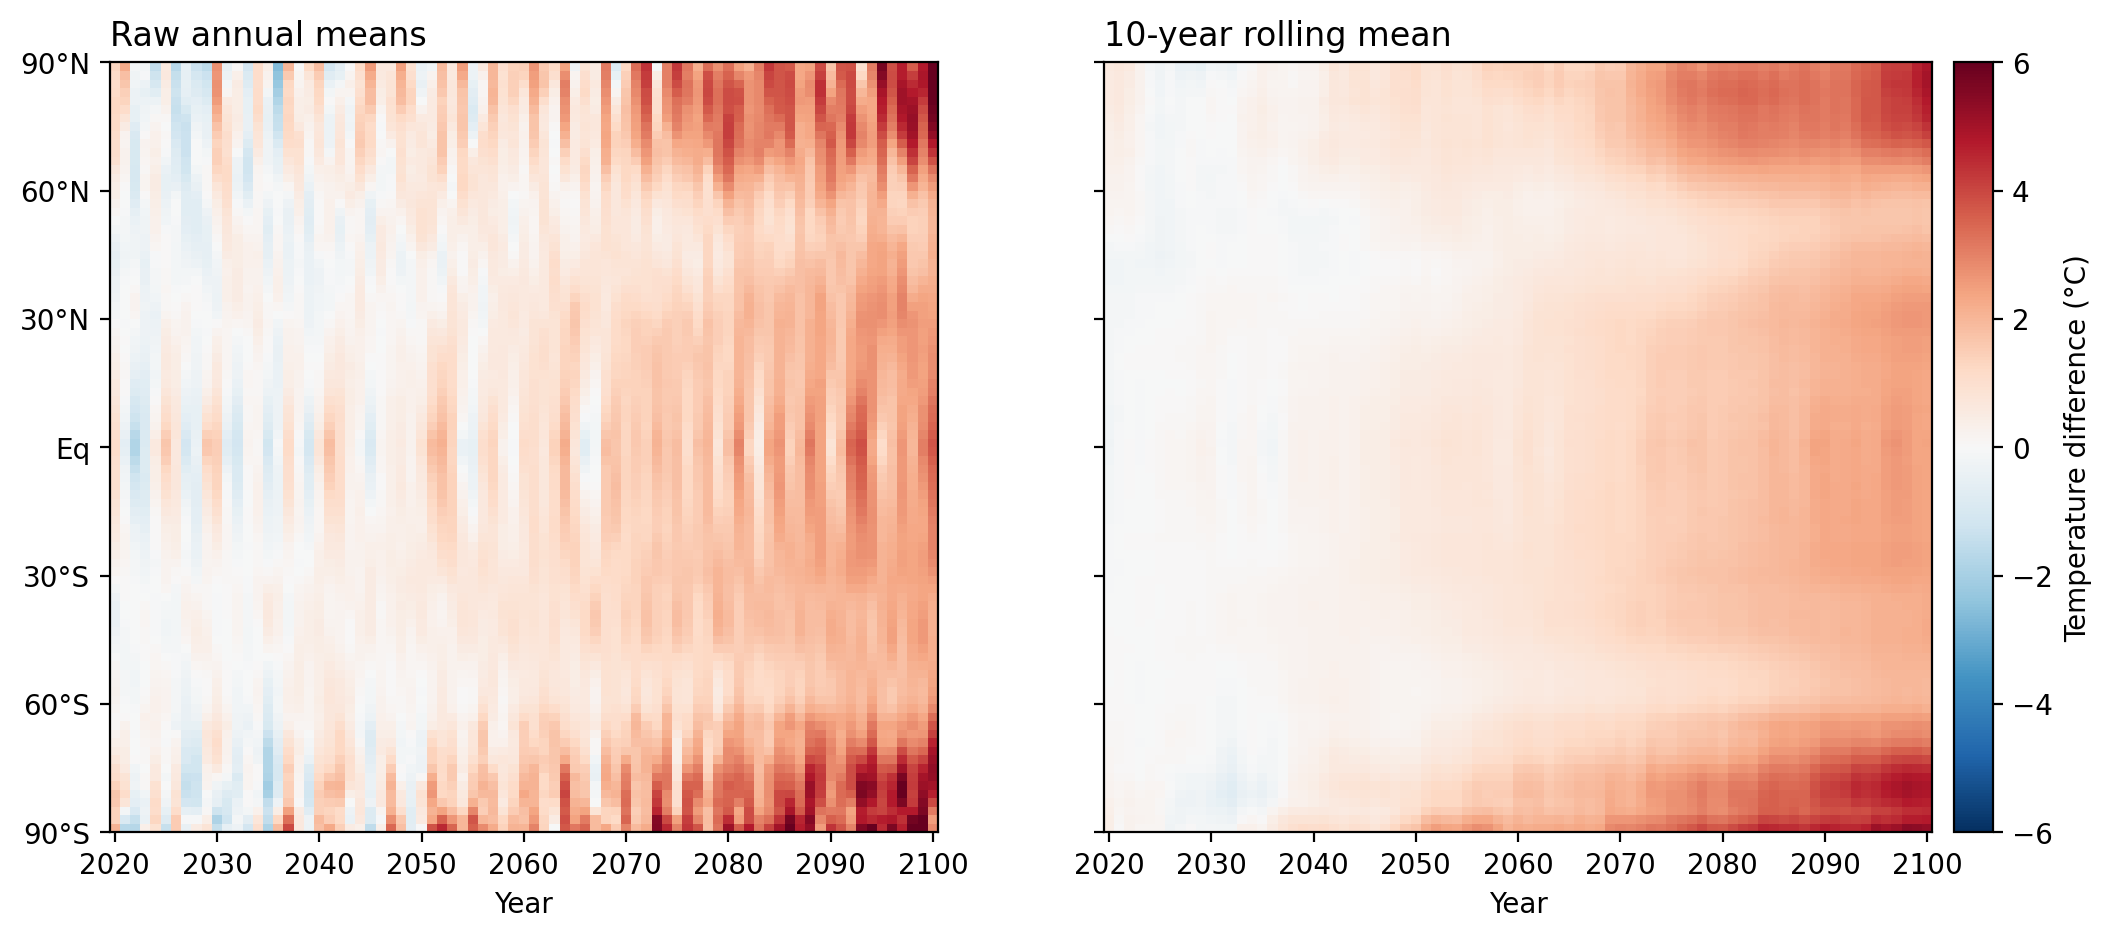

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, data, title in [(axes[0], gap, 'Raw annual means'), (axes[1], gap_10yr, '10-year rolling mean')]:
    mesh = ax.pcolormesh(data.year, data.lat, data.T, cmap='RdBu_r', vmin=-LIMIT, vmax=LIMIT, shading='nearest')
    ax.set_title(title, loc='left')
    ax.set_xlabel('Year')
axes[0].set_yticks(LAT_TICKS, LAT_LABELS)
fig.colorbar(mesh, ax=axes, label='Temperature difference (°C)', pad=0.01)
plt.show()

### Reading one column: latitude profiles

Each line is a vertical slice through the heatmap. This is the "linked view" idea: hovering a year column in D3 could draw this profile next to it, or move the map's year slider.

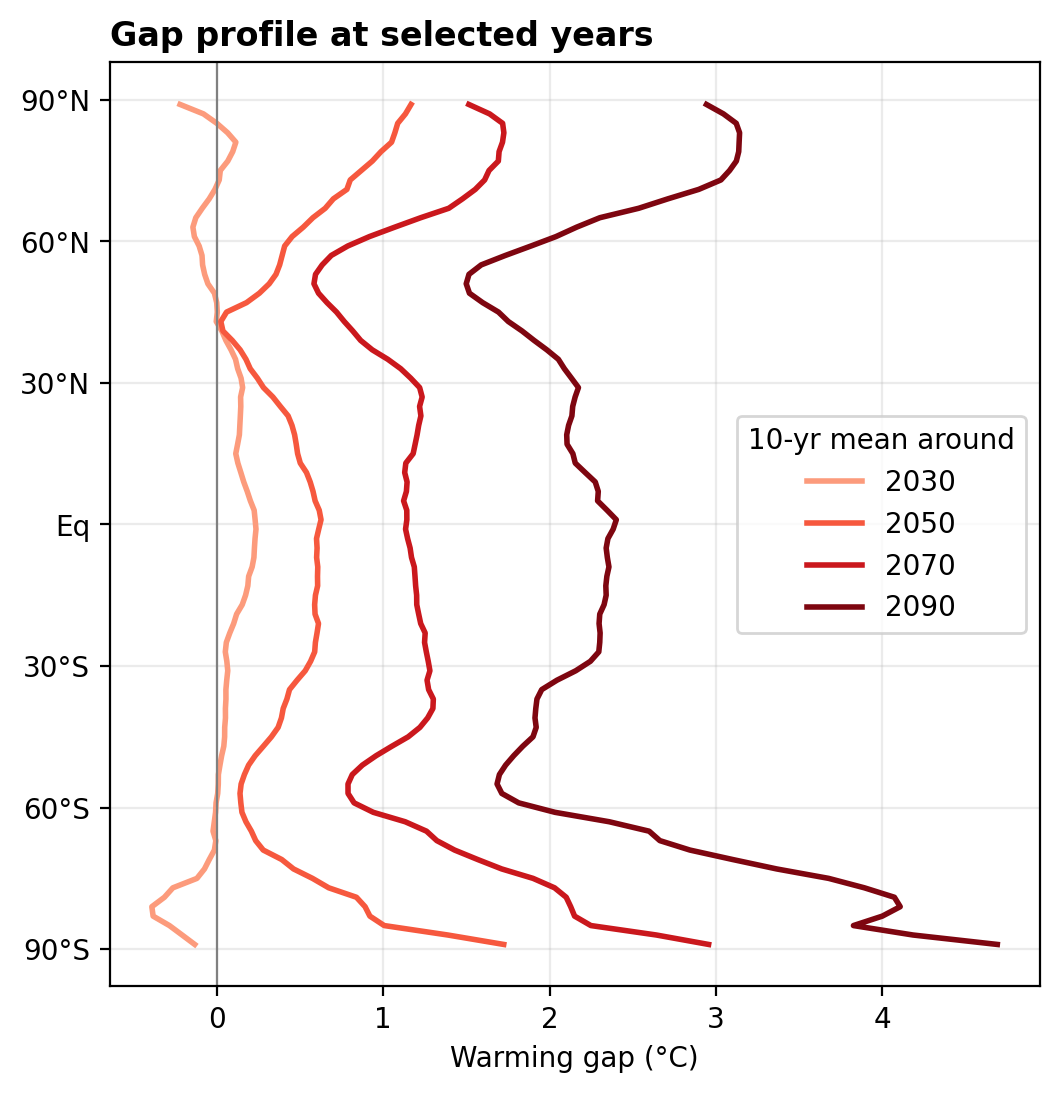

In [25]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = plt.cm.Reds(np.linspace(0.35, 0.95, 4))
for color, year in zip(colors, [2030, 2050, 2070, 2090]):
    ax.plot(gap_10yr.sel(year=year), gap_10yr.lat, color=color, lw=2, label=str(year))
ax.axvline(0, color='grey', lw=0.8)
ax.set_yticks(LAT_TICKS, LAT_LABELS)
ax.set_xlabel('Warming gap (°C)')
ax.set_title('Gap profile at selected years', loc='left', fontweight='bold')
ax.legend(title='10-yr mean around')
ax.grid(alpha=0.25)
plt.show()

### Export for D3

One row per (year, latitude): 81 years × 90 latitudes = 7,290 rows, small enough to load directly in the browser with `d3.csv`.

In [26]:
from pathlib import Path

Path('data').mkdir(exist_ok=True)
export = (
    xr.Dataset({'gap_c': gap, 'gap_10yr_c': gap_10yr})
    .to_dataframe()
    .reset_index()[['year', 'lat', 'gap_c', 'gap_10yr_c']]
    .round(3)
)
export.to_csv('data/gap-year-latitude.csv', index=False)
print(len(export), 'rows')
export.head()

7290 rows


,year,lat,gap_c,gap_10yr_c
0,2020,-89.0,2.100,0.398
1,2021,-89.0,-1.646,0.045
2,2022,-89.0,-1.732,0.243
3,2023,-89.0,0.361,0.127
4,2024,-89.0,0.897,0.122


### How this becomes the D3 chart

```js
const data = await d3.csv("data/gap-year-latitude.csv", d3.autoType);

const x = d3.scaleBand(d3.range(2020, 2101), [0, width]);              // one column per year
const y = d3.scaleBand([...new Set(data.map(d => d.lat))].sort(d3.descending), [0, height]);
const color = d3.scaleDiverging([LIMIT, 0, -LIMIT], d3.interpolateRdBu); // red = warmer, same as map

svg.selectAll("rect")
  .data(data)
  .join("rect")
    .attr("x", d => x(d.year))
    .attr("y", d => y(d.lat))
    .attr("width", x.bandwidth())
    .attr("height", y.bandwidth())
    .attr("fill", d => color(d.gap_10yr_c));
```

Interaction ideas that tie it to the rest of the page:

- **Hover** a cell to see a tooltip with the year, latitude and gap.
- **Click** a column to set the map's year slider to that year, and draw a vertical marker on the heatmap that follows the slider.
- **Toggle** between raw annual values and the 10-year mean (the comparison above).
- **Annotate** two or three spots directly on the chart, such as the Arctic and the Southern Ocean.